# GenVerOpt reproduction — Stage 3b: MM-IQ layout and label probe
Findings from Stage 3a: the mirror has one split of 2,710 rows with columns `image`, `problem`, `solution` only (no paradigm label), and each image contains the question grid and the four options together.
This notebook measures how regular the layouts are, so we can decide how to extract candidates. **Generated, not yet run on the real data.**

In [1]:
!pip -q install datasets pillow matplotlib
import random, numpy as np, re
from collections import Counter
from datasets import load_dataset
import matplotlib.pyplot as plt
random.seed(0); np.random.seed(0)
ds = load_dataset("afdsafas/MMIQ")["train"]
print(len(ds), ds.features)

data/train_1.parquet: reconstructing file:   0%|          |  0.00B /  116MB            

data/train_1.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2710 [00:00<?, ? examples/s]

2710 {'image': Image(mode=None, decode=True), 'problem': Value('string'), 'solution': Value('string')}


## 1. Labels and prompt text

In [2]:
def parse_answer(s):
    m = re.search(r"<answer>\s*([A-D])\s*</answer>", s)
    return "ABCD".index(m.group(1)) if m else None

ans = [parse_answer(s) for s in ds["solution"]]
print("unparsed answers:", sum(a is None for a in ans))
print("answer distribution:", Counter(ans))
probs = Counter(ds["problem"])
print("distinct problem strings:", len(probs))
for p, n in probs.most_common(5): print(n, "|", p[:140])

unparsed answers: 0
answer distribution: Counter({2: 696, 1: 690, 3: 684, 0: 640})
distinct problem strings: 718
1121 | Choose the most appropriate option from the given four choices to fill in the question mark, so that it presents a certain regularity:
87 | Choose the most appropriate option from the given four options to present a certain regularity:
80 | Choose the most appropriate option from the four given choices to fill in the question mark, so that it presents a certain regularity:
56 | Among the four figures on the right, only one is formed by combining the four figures on the left (only through translation up, down, left, 
55 | Which of the following options conforms to the given pattern of changes in the figures? ( ).


## 2. Image size statistics

width  min/median/max: 110 598 8128
height min/median/max: 46 249 3381
modes: Counter({'RGBA': 1592, 'RGB': 736, 'P': 252, 'L': 127, 'CMYK': 2, '1': 1})


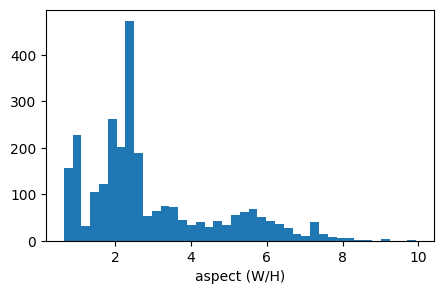

In [3]:
sizes = [im.size for im in ds["image"]]          # decodes all images once (~116 MB parquet)
W = np.array([s[0] for s in sizes]); H = np.array([s[1] for s in sizes])
print("width  min/median/max:", W.min(), int(np.median(W)), W.max())
print("height min/median/max:", H.min(), int(np.median(H)), H.max())
print("modes:", Counter(im.mode for im in ds["image"]))
plt.figure(figsize=(5,3)); plt.hist(W/H, bins=40); plt.xlabel("aspect (W/H)"); plt.show()

## 3. Option-label probe
Hypothesis (from 4 samples only): the last ink-bearing row band is the "A B C D" label row, and its 4 glyph clusters give the x-centres of the four options.
A hit means exactly 4 clusters. A hit does not prove the crops are right; we check visually in section 4.

In [4]:
def runs(mask, min_gap):
    """Maximal runs of True in a 1-D bool array; runs separated by < min_gap False values are merged."""
    idx = np.flatnonzero(mask)
    if idx.size == 0: return []
    out, s, prev = [], idx[0], idx[0]
    for i in idx[1:]:
        if i - prev > min_gap:
            out.append((s, prev + 1)); s = i
        prev = i
    out.append((s, prev + 1))
    return out

def probe(im, thr=200):
    g = np.asarray(im.convert("L"))
    ink = g < thr
    h, w = ink.shape
    rbands = runs(ink.any(1), min_gap=2)
    if not rbands: return None
    r0, r1 = rbands[-1]
    cols = runs(ink[r0:r1].any(0), min_gap=max(3, int(0.01 * w)))
    return dict(label_band=(r0, r1), n_clusters=len(cols), clusters=cols, n_row_bands=len(rbands), H=h, W=w)

res = [probe(im) for im in ds["image"]]
nc = Counter(r["n_clusters"] if r else -1 for r in res)
print("clusters in last row band:", dict(sorted(nc.items())))
print("fraction with exactly 4:", round(nc[4] / len(res), 3))
band_h = np.array([(r["label_band"][1] - r["label_band"][0]) / r["H"] for r in res if r])
print("last-band height / image height: median", round(float(np.median(band_h)), 3), "max", round(float(band_h.max()), 3))

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


clusters in last row band: {1: 577, 2: 78, 3: 33, 4: 1781, 5: 21, 6: 196, 7: 13, 8: 7, 9: 1, 10: 1, 11: 1, 12: 1}
fraction with exactly 4: 0.657
last-band height / image height: median 0.074 max 1.0


## 4. Visual check: 12 random samples (green = last row band) and 12 failures

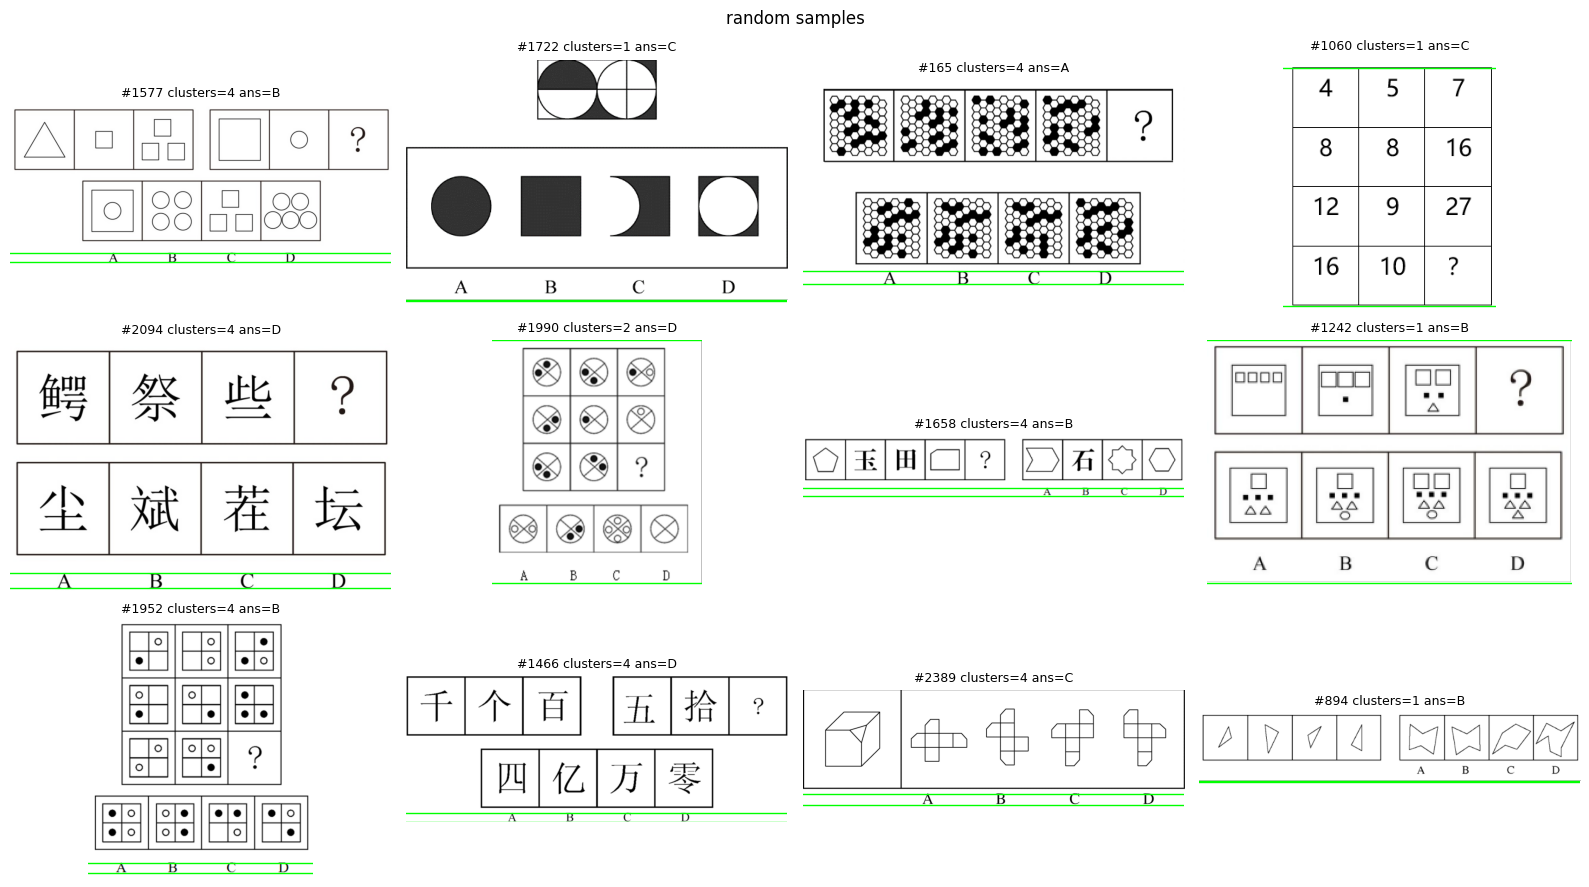

failures: 929


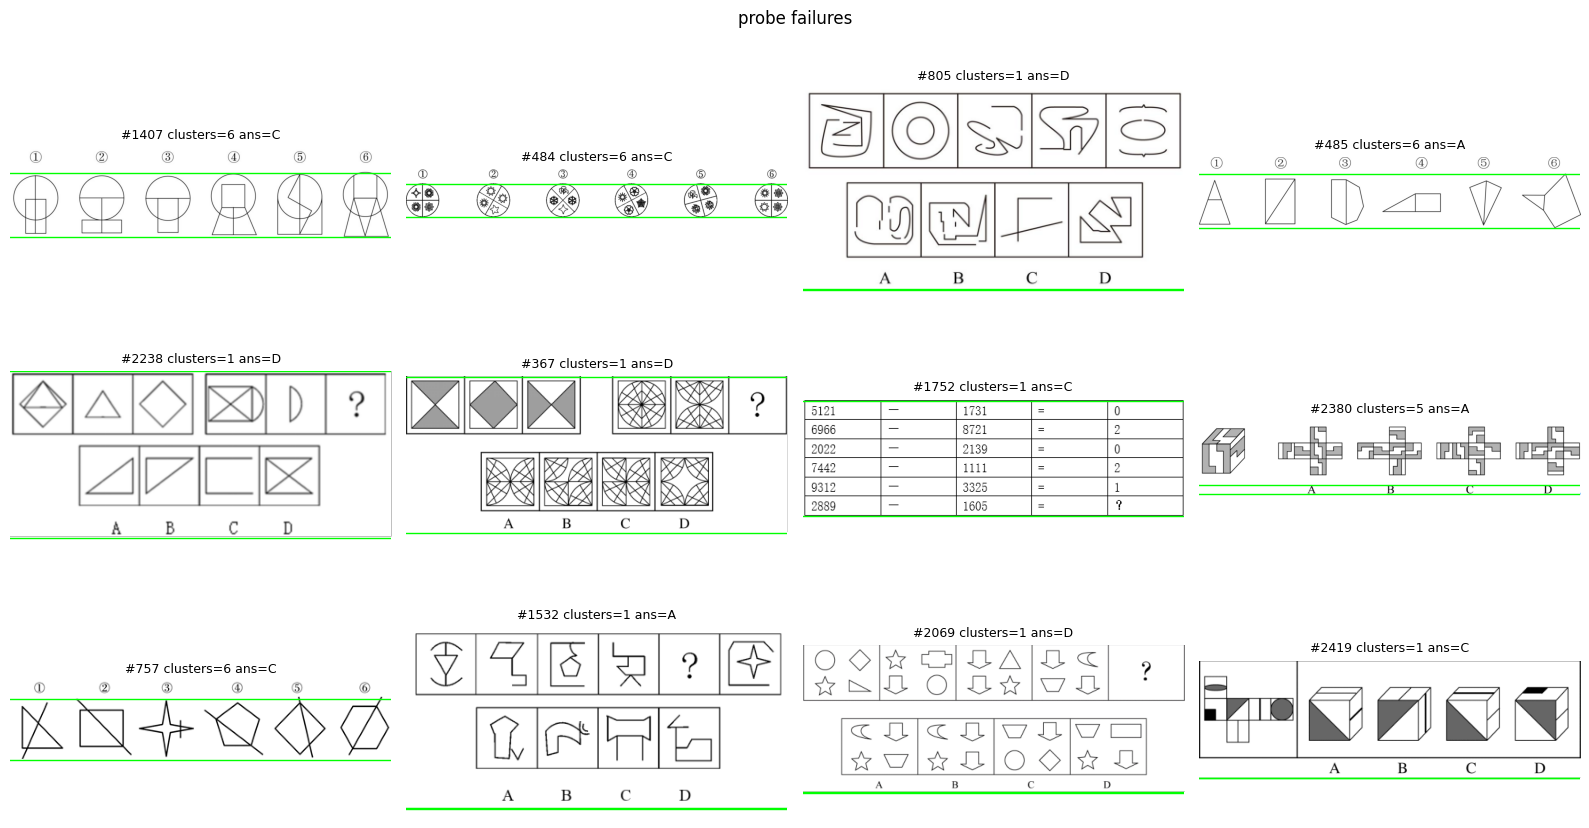

In [5]:
def show(indices, title, fname):
    fig, axes = plt.subplots(3, 4, figsize=(16, 9))
    for ax, i in zip(axes.ravel(), indices):
        im = ds[i]["image"]; r = res[i]
        ax.imshow(im); ax.axis("off")
        if r:
            ax.axhline(r["label_band"][0], color="lime", lw=1); ax.axhline(r["label_band"][1], color="lime", lw=1)
            ax.set_title(f"#{i} clusters={r['n_clusters']} ans={'ABCD'[ans[i]]}", fontsize=9)
    plt.suptitle(title); plt.tight_layout(); plt.savefig(fname, dpi=110); plt.show()

random_idx = random.sample(range(len(ds)), 12)
show(random_idx, "random samples", "/content/probe_random.png")
fails = [i for i, r in enumerate(res) if (r is None or r["n_clusters"] != 4)]
print("failures:", len(fails))
if fails: show(random.sample(fails, min(12, len(fails))), "probe failures", "/content/probe_failures.png")

Send back the printed output of sections 1–3 and the two saved figures (random samples and failures).